# O objetivo é ler o arquivo de estatísticas da Loja do Google **googleplaystore.csv**, processar e gerar gráficos de análise. Realize as seguintes atividades sobre o dataset **utilizando as bibliotecas Pandas e Matplotlib**.

## Etapa 1: ambiente

### Leia o arquivo csv googleplaystore.csv

In [1]:
# Importando as bibliotecas para o exercício
import pandas as pd
import matplotlib as plt
import numpy as np
# importando módulos adicionais para gerar gráficos melhores
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

In [2]:
# Abrindo o csv
df = pd.read_csv('/content/googleplaystore.csv')
df.shape

(10841, 13)

In [3]:
# Abrindo as primeiras linhas do dataset
df.head(2)

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up


## Etapa 2 - Desenvolvimento

### Fazendo um levantamento da organização do dataset primeiro antes de fazer os gráficos

In [4]:
# Imprimindo informações sobre o dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


In [5]:
'''
  Quando fui fazer o gráfico de pizza percebi que apareceu uma linha na qual não tinha
  o valor da categoria, por ser uma linha somente, vou eliminar essa linha.
'''

# Obtendo as linhas onde a categoria é '1.9'
linhas_categoria = df.loc[df['Category'] == '1.9']

# Imprimindo as linhas
linhas_categoria

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,3.0M,"1,000+",Free,0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN


In [6]:
# Mantendo todas as linhas do dataset, menos a linha com '1,9'
df = df[df['Category'] != '1.9']

In [7]:
# Obtendo uma lista das categorias únicas
categorias = df['Category'].unique()

# Imprimindo a lista de categorias
for categoria in categorias:
    print(categoria)

ART_AND_DESIGN
AUTO_AND_VEHICLES
BEAUTY
BOOKS_AND_REFERENCE
BUSINESS
COMICS
COMMUNICATION
DATING
EDUCATION
ENTERTAINMENT
EVENTS
FINANCE
FOOD_AND_DRINK
HEALTH_AND_FITNESS
HOUSE_AND_HOME
LIBRARIES_AND_DEMO
LIFESTYLE
GAME
FAMILY
MEDICAL
SOCIAL
SHOPPING
PHOTOGRAPHY
SPORTS
TRAVEL_AND_LOCAL
TOOLS
PERSONALIZATION
PRODUCTIVITY
PARENTING
WEATHER
VIDEO_PLAYERS
NEWS_AND_MAGAZINES
MAPS_AND_NAVIGATION


### Convertendo os valores das colunas para fazer os gráficos e os calculos

In [8]:
'''
Convertendo o tipo da coluna 'Installs'
'''
# Convertendo 'Installs' para string
df['Installs'] = df['Installs'].astype(str)
# Removendo o '+' e as vírgulas de 'Installs'
df['Installs'] = df['Installs'].str.replace('+', '').str.replace(',', '')
# Convertendo 'Installs' para int e 'Price' para float
df['Installs'] = df['Installs'].astype(int)

'''
Convertendo o tipo da coluna 'Price'
'''
# Removendo o '$' de  'Price'
df['Price'] = df['Price'].astype(str)
# Removendo o '$' de 'Price'
df['Price'] = df['Price'].str.replace('$', '')
# Convertendo 'Price' para float
df['Price'] = df['Price'].astype(float)

'''
Convertendo o tipo da coluna 'Reviews'
'''
# Convertendo 'Reviews' para int
df['Reviews'] = df['Reviews'].astype(int)

'''
Convertendo o tipo da coluna 'Rating'
'''
# Convertendo 'Rating' para float
df['Rating'] = df['Rating'].astype(float)

'''
Convertendo o tipo da coluna 'Last Updated'
'''
# Convertendo 'Last Updated' para datetime
df['Last Updated'] = pd.to_datetime(df['Last Updated'])

'''
Convertendo o tipo da coluna 'Size'

Para essa coluna, o 'Size' tem campos = 'Varies with device', nesse caso, entendo que
esses valores não podem ser retirados, e também não se deve colocar valores relacionados
a média, mediana, ou moda, pois isso geraria valores que não podem corresponder a realidade
para determinado app. Então optei por deixar o valor como 'NaN' e depois substituir por zero.
'''
# Substituindo 'Varies with device' por 0
df['Size'] = df['Size'].replace('Varies with device', np.nan)
# Convertendo 'M' para '000k'
df['Size'] = df['Size'].replace({'M': '000'}, regex=True)
# Removendo 'k' e convertendo para float
df['Size'] = df['Size'].str.replace('k', '').astype(float)

In [9]:
# Obtendo valores únicos
unique_values = df['Installs'].unique()
unique_values.sort()

# Imprimindo os valores únicos
print(unique_values)

[         0          1          5         10         50        100
        500       1000       5000      10000      50000     100000
     500000    1000000    5000000   10000000   50000000  100000000
  500000000 1000000000]


In [10]:
# Obtendo valores únicos
unique_values = df['Content Rating'].unique()
unique_values.sort()

# Imprimindo os valores únicos
print(unique_values)

['Adults only 18+' 'Everyone' 'Everyone 10+' 'Mature 17+' 'Teen' 'Unrated']


In [11]:
# Obtendo valores únicos
unique_price = df['Price'].unique()

unique_price.sort()

# Imprimindo os valores únicos
print(unique_price)

[  0.     0.99   1.     1.04   1.2    1.26   1.29   1.49   1.5    1.59
   1.61   1.7    1.75   1.76   1.96   1.97   1.99   2.     2.49   2.5
   2.56   2.59   2.6    2.9    2.95   2.99   3.02   3.04   3.08   3.28
   3.49   3.61   3.88   3.9    3.95   3.99   4.29   4.49   4.59   4.6
   4.77   4.8    4.84   4.85   4.99   5.     5.49   5.99   6.49   6.99
   7.49   7.99   8.49   8.99   9.     9.99  10.    10.99  11.99  12.99
  13.99  14.    14.99  15.46  15.99  16.99  17.99  18.99  19.4   19.9
  19.99  24.99  25.99  28.99  29.99  30.99  33.99  37.99  39.99  46.99
  74.99  79.99  89.99 109.99 154.99 200.   299.99 379.99 389.99 394.99
 399.99 400.  ]


In [12]:
# Obtendo valores únicos
unique_size = df['Size'].unique()

unique_size.sort()

# Imprimindo os valores únicos
print(unique_size)

[1.00e+00 1.10e+00 1.20e+00 1.30e+00 1.40e+00 1.50e+00 1.60e+00 1.70e+00
 1.80e+00 1.90e+00 2.00e+00 2.10e+00 2.20e+00 2.30e+00 2.40e+00 2.50e+00
 2.60e+00 2.70e+00 2.80e+00 2.90e+00 3.00e+00 3.10e+00 3.20e+00 3.30e+00
 3.40e+00 3.50e+00 3.60e+00 3.70e+00 3.80e+00 3.90e+00 4.00e+00 4.10e+00
 4.20e+00 4.30e+00 4.40e+00 4.50e+00 4.60e+00 4.70e+00 4.80e+00 4.90e+00
 5.00e+00 5.10e+00 5.20e+00 5.30e+00 5.40e+00 5.50e+00 5.60e+00 5.70e+00
 5.80e+00 5.90e+00 6.00e+00 6.10e+00 6.20e+00 6.30e+00 6.40e+00 6.50e+00
 6.60e+00 6.70e+00 6.80e+00 6.90e+00 7.00e+00 7.10e+00 7.20e+00 7.30e+00
 7.40e+00 7.50e+00 7.60e+00 7.70e+00 7.80e+00 7.90e+00 8.00e+00 8.10e+00
 8.20e+00 8.30e+00 8.40e+00 8.50e+00 8.60e+00 8.70e+00 8.80e+00 8.90e+00
 9.00e+00 9.10e+00 9.20e+00 9.30e+00 9.40e+00 9.50e+00 9.60e+00 9.70e+00
 9.80e+00 9.90e+00 1.00e+01 1.10e+01 1.40e+01 1.70e+01 1.80e+01 2.00e+01
 2.30e+01 2.40e+01 2.50e+01 2.60e+01 2.70e+01 2.80e+01 2.90e+01 3.30e+01
 3.40e+01 3.90e+01 4.10e+01 4.40e+01 4.50e+01 4.80e

In [13]:
# Contando valores NaN da coluna 'Size'
nan_count = df['Size'].isna().sum()
print(f"Quantidade de valores NaN: {nan_count}")

# Contando valores 0 da coluna 'Size'
zero_count = (df['Size'] == 0).sum()
print(f"Quantidade de valores 0: {zero_count}")

Quantidade de valores NaN: 1695
Quantidade de valores 0: 0


In [14]:
# Preenchendo os valores NaN da coluna 'Size' por 0
df['Size'] = df['Size'].fillna(0)

In [15]:
# faz a contagem dos valores nulos
df_na_sum = df.isna().sum()
df_na_sum

App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       0
Genres               0
Last Updated         0
Current Ver          8
Android Ver          2
dtype: int64

In [16]:
from sklearn.impute import KNNImputer

'''

  Usei o algoritmo K-Nearest Neighbors (KNN) para preencher os valores faltantes
  na coluna ‘Rating’. O KNN prevê valores com base em quão semelhante é o dado em relação
  aos seus vizinhos mais próximos.

  Este código substituirá todos os valores faltantes na coluna ‘Rating’ com base na
  média dos 5 vizinhos mais próximos.

'''

# Criando o imputador KNN
imputer = KNNImputer(n_neighbors=5)

# Substitua todas as entradas não numéricas por NaN para o KNN funcionar
df['Rating'] = pd.to_numeric(df['Rating'], errors='coerce')

# Realize a imputação KNN na coluna 'Rating'
df['Rating'] = imputer.fit_transform(df[['Rating']])

In [17]:
# Preenchendo os valores faltantes com a moda da coluna 'Type'
for coluna in ['Type', 'Content Rating', 'Current Ver', 'Android Ver']:
    df[coluna].fillna(df[coluna].mode()[0], inplace=True)

In [18]:
# faz a contagem dos valores nulos
df_na_sum = df.isna().sum()
df_na_sum

App               0
Category          0
Rating            0
Reviews           0
Size              0
Installs          0
Type              0
Price             0
Content Rating    0
Genres            0
Last Updated      0
Current Ver       0
Android Ver       0
dtype: int64

### 1 Retirando as linhas duplicadas do dataset

In [19]:
# Criação de uma variável que vai armazenar os valores duplicados
df_duplicates = df[df.duplicated()]

# Se houver valores duplicados, imprima
if len(df_duplicates)>0:
    print('Amostras duplicadas:\n', df_duplicates.count())
else:
    print('Não existem valores duplicados')

Amostras duplicadas:
 App               483
Category          483
Rating            483
Reviews           483
Size              483
Installs          483
Type              483
Price             483
Content Rating    483
Genres            483
Last Updated      483
Current Ver       483
Android Ver       483
dtype: int64


In [20]:
'''
Para cada grupo de amostras duplicadas, mantém uma e apaga as demais
'''

# remove as amostras duplicadas, mantendo apenas a primeira ocorrencia
df = df.drop_duplicates(keep = 'first')


#dataset sem os valores duplicados
display(df.shape)

(10357, 13)

In [21]:
# Encontrando nomes de aplicativos duplicados
duplicados = df['App'].duplicated()

# Contando o número de duplicados
num_duplicados = duplicados.sum()

print(f"Há {num_duplicados} aplicativos com nomes duplicados na lista.")

Há 698 aplicativos com nomes duplicados na lista.


In [22]:
# Agrupando por 'App' e encontrando na linha o maior número de 'Reviews' para cada aplicativo
df = df.loc[df.groupby('App')['Reviews'].idxmax()]
df.shape

(9659, 13)

In [23]:
# Reimprimindo informações sobre o dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9659 entries, 8884 to 882
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   App             9659 non-null   object        
 1   Category        9659 non-null   object        
 2   Rating          9659 non-null   float64       
 3   Reviews         9659 non-null   int64         
 4   Size            9659 non-null   float64       
 5   Installs        9659 non-null   int64         
 6   Type            9659 non-null   object        
 7   Price           9659 non-null   float64       
 8   Content Rating  9659 non-null   object        
 9   Genres          9659 non-null   object        
 10  Last Updated    9659 non-null   datetime64[ns]
 11  Current Ver     9659 non-null   object        
 12  Android Ver     9659 non-null   object        
dtypes: datetime64[ns](1), float64(3), int64(2), object(7)
memory usage: 1.0+ MB


### **2** Faça um gráfico de barras contendo os top 5 por números de instalação

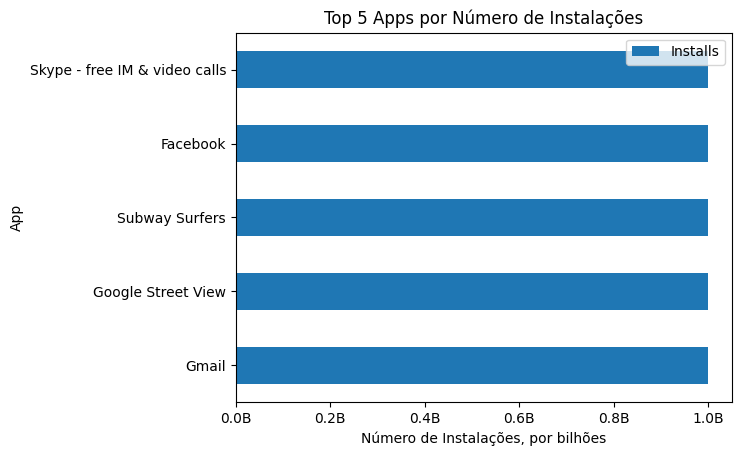

In [24]:
'''
Nesse gráfico, notei que alguns apps apareciam mais de uma vez na lista, mesmo retirando os
valores duplicados. O que muda de uma linha para outra ou é o números de reviews ou a data de
atualização.
'''

# Ordenando em ordem decrescente e pegando os top 5
top_5_apps = df.sort_values(by='Installs', ascending=False).head(5)

# Plotando o gráfico
ax = top_5_apps.plot(kind='barh', x='App', y='Installs')

# Ajustando os valores do eixo x para bilhões
ax.xaxis.set_major_formatter(lambda x, _: '{:.1f}B'.format(x*1e-9))

# Adicionando título ao gráfico e aos eixos
plt.title('Top 5 Apps por Número de Instalações')
plt.xlabel('Número de Instalações, por bilhões')
plt.ylabel('App')

# Mostrando o gráfico
plt.show()

### **3** Faça um gráfico de pizza (pie chart) mostrando as categorias de aps existentes no dataset de acordo com a frêquencia em que elas aparecem.

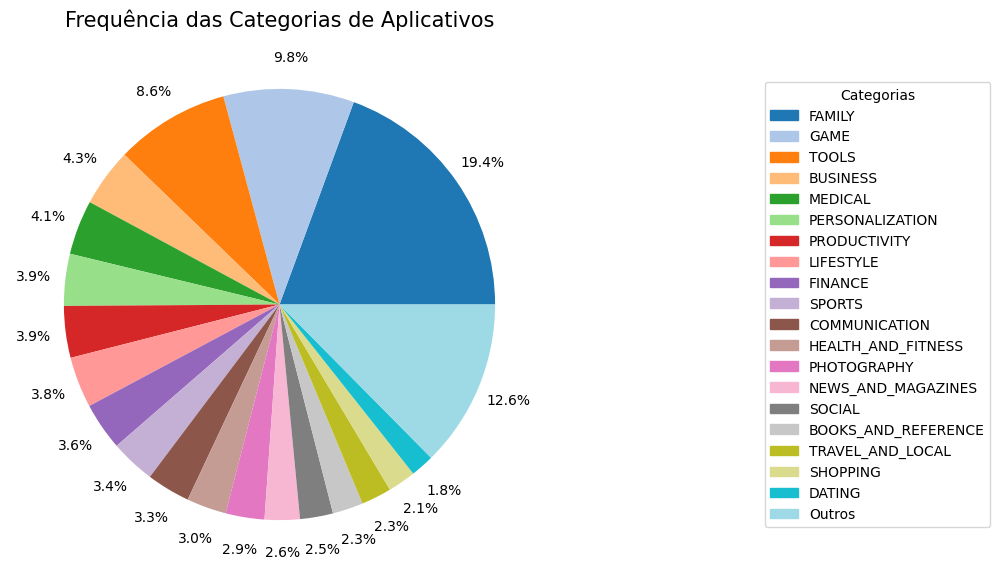

In [25]:
'''
Ao tentar elaborar o gráfico, me deparei com uma representação visual insatisfatória
ao inserir os valores. A minha primeira ideia foi alocar esses valores em uma legenda distinta.
No entanto, me deparei com uma limitação no número de categorias que o gráfico poderia comportar.
Como solução, agrupei as categorias residuais de menor expressividade num único agrupamento denominado ‘Outros’.

'''

# Definindo o número de categorias mostradas separadamente
num_categorias = 19

# Calcula a contagem e a porcentagem de cada categoria
category_counts = df['Category'].value_counts()
category_percentages = category_counts / category_counts.sum() * 100

# Agrupa as categorias com menos frequência em 'Outros'
if len(category_counts) > num_categorias:
    category_counts = category_counts[:num_categorias]
    category_counts.loc['Outros'] = df['Category'].value_counts()[num_categorias:].sum()

    category_percentages = category_percentages[:num_categorias]
    category_percentages.loc['Outros'] = df['Category'].value_counts(normalize=True)[num_categorias:].sum() * 100

# Cria a figura e os eixos
fig, ax = plt.subplots(figsize=(10, 7))

# Cria o gráfico de pizza
colors = plt.cm.tab20.colors[:len(category_counts.index)]
wedges, texts, autotexts = ax.pie(category_counts, labels=None, autopct="%1.1f%%", colors=colors, pctdistance=1.15)

# Cria a tabela de legenda
legend_labels = ['{}'.format(i) for i, in zip(category_counts.index)]

# Cria patches para a legenda -- serve para criar uma legenda personalizada para o gráfico--
patches = [Patch(facecolor=c, edgecolor=c, label=l) for c, l in zip(colors, legend_labels)]

# Adiciona a legenda ao gráfico
ax.legend(handles=patches, title="Categorias", loc="center left", bbox_to_anchor=(1.40, 0.5), borderaxespad=0.)

plt.title("Frequência das Categorias de Aplicativos", loc="center", fontsize=15)
plt.show()

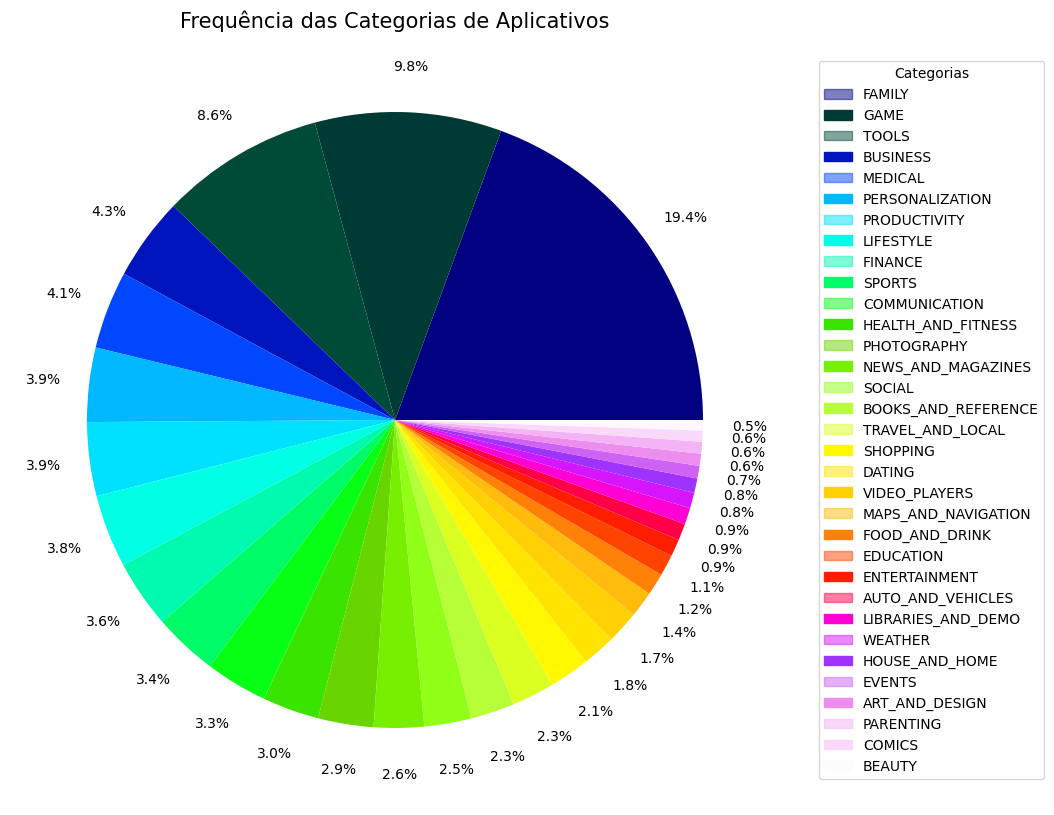

In [26]:
'''
Para poder cumprir os requisitos fiz outro gráfico com todas as colunas.
'''

# Calcula a contagem e a porcentagem de cada categoria
category_counts = df['Category'].value_counts()
category_percentages = category_counts / category_counts.sum() * 100

# Cria a figura e os eixos
fig, ax = plt.subplots(figsize=(13, 10))

# Cria o gráfico de pizza
colors = plt.cm.gist_ncar(np.linspace(0, 1, len(category_counts.index)))
wedges, texts, autotexts = ax.pie(category_counts, labels=None, colors=colors, autopct='%1.1f%%', pctdistance=1.15)

# Cria a tabela de legenda
legend_labels = ['{}'.format(i) for i, in zip(category_counts.index)]

# Cria patches para a legenda -- serve para criar uma legenda personalizada para o gráfico--
patches = [Patch(facecolor=c, edgecolor=c, label=l, alpha=0.5 if i%2==0 else 1) for i, (c, l) in enumerate(zip(colors, legend_labels))]

# Adiciona a legenda ao gráfico
ax.legend(handles=patches, title="Categorias", loc="center left", bbox_to_anchor=(1.05, 0.5), borderaxespad=0.)

plt.title("Frequência das Categorias de Aplicativos", loc="center", fontsize=15)
plt.show()


### 4. Mostre qual o app mais caro do dataset

In [27]:
# Organizando os valores e ordenando decrescente
app_mais_caro = df.sort_values(by=['Price'], ascending=False).head(1)
print(f'O app mais caro do dataset é: "{app_mais_caro["App"].values[0]}" e custa: R$ {app_mais_caro["Price"].values[0]}')

O app mais caro do dataset é: "I'm Rich - Trump Edition" e custa: R$ 400.0


### 5. Mostre quantos apps são cosiderados como **'Mature 17+'**

In [28]:
# Pricurando as linhas que possuem 'Mature 17+' como valor e mostrando a quantidade
mature_17 = df[df['Content Rating'] == 'Mature 17+'].shape[0]
print(f'A quantidade de aplicativos com classificação "Mature 17+" é: {mature_17}')

A quantidade de aplicativos com classificação "Mature 17+" é: 393


### 6. Mostre o top 10 apps por número de reviews, bem como o respectivo número de reviews. Ordene a lista de forma decrescente de reviews

In [29]:
# Organizando os valores das reviews e ordenando descrescente
top_10 = df.sort_values(by=['Reviews'], ascending=False).head(10)
for index, row in top_10.iterrows():
    print(f'App: {row["App"]:<50} Reviews: {row["Reviews"]}')

App: Facebook                                           Reviews: 78158306
App: WhatsApp Messenger                                 Reviews: 69119316
App: Instagram                                          Reviews: 66577446
App: Messenger – Text and Video Chat for Free           Reviews: 56646578
App: Clash of Clans                                     Reviews: 44893888
App: Clean Master- Space Cleaner & Antivirus            Reviews: 42916526
App: Subway Surfers                                     Reviews: 27725352
App: YouTube                                            Reviews: 25655305
App: Security Master - Antivirus, VPN, AppLock, Booster Reviews: 24900999
App: Clash Royale                                       Reviews: 23136735


### 7 - 8. Crie pelo menos mais 2 cálculos sobre o dataset e apresente um em formato de lista e outro em formato de valor. E crie gráficos para representar os valores encontrados

In [30]:
'''
Para essa etapa do desafio optei por criar uma lista da quantidade de apps pela
classificação de conteúdo na qual ele foi classificado, depois criei um gráfico de pontos.
'''

# Contar a quantidade de aplicativos para cada classificação de conteúdo
contagem_apps = df['Content Rating'].value_counts()

# Imprimir a contagem
for index, value in contagem_apps.items():
    print(f'Classificação de Conteúdo: {index:<20} Quantidade de Aplicativos: {value}')

Classificação de Conteúdo: Everyone             Quantidade de Aplicativos: 7903
Classificação de Conteúdo: Teen                 Quantidade de Aplicativos: 1036
Classificação de Conteúdo: Mature 17+           Quantidade de Aplicativos: 393
Classificação de Conteúdo: Everyone 10+         Quantidade de Aplicativos: 322
Classificação de Conteúdo: Adults only 18+      Quantidade de Aplicativos: 3
Classificação de Conteúdo: Unrated              Quantidade de Aplicativos: 2


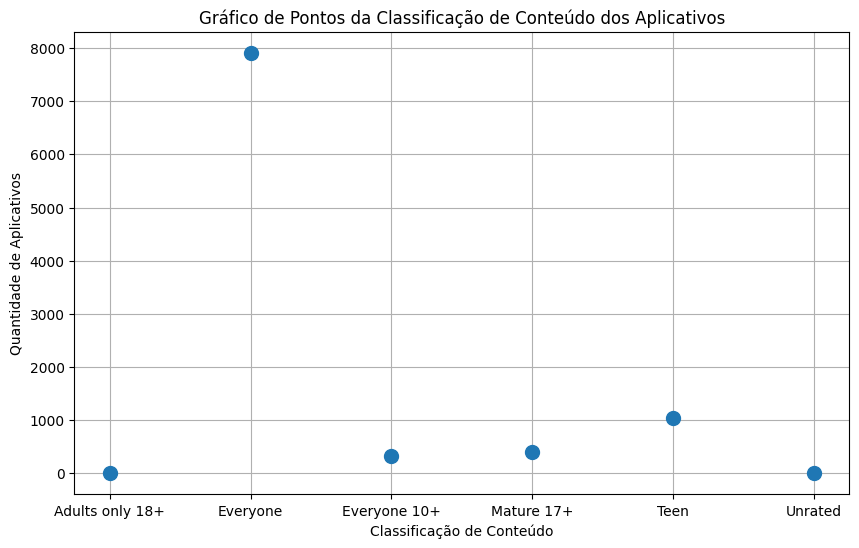

In [31]:
plt.figure(figsize=(10,6))
df['Content Rating'].value_counts().sort_index().plot(style='o', ms=10)  # ms is marker size
plt.title('Gráfico de Pontos da Classificação de Conteúdo dos Aplicativos')
plt.xlabel('Classificação de Conteúdo')
plt.ylabel('Quantidade de Aplicativos')
plt.grid(True)
plt.show()

In [32]:
from datetime import datetime

# Criando uma nova coluna para o ano de atualização
df['Update Year'] = df['Last Updated'].dt.year

# Filtrando os dados para o ano de 2018
df_2018 = df[df['Update Year'] == 2018]

# Contando a quantidade de aplicativos instalados em 2018
contagem_apps_2018 = df_2018['App'].count()

print(f'Quantidade de aplicativos instalados no ano de 2018: {contagem_apps_2018}')

Quantidade de aplicativos instalados no ano de 2018: 6287


In [33]:
'''
Queria nesse gráfico mostrar como um painel os valores encontrados nessa busca, mas com o matplotlib
não consegui fazer. Então para esse último desafio optei por imprimir um gráfico com a quantidade de
instalação por mês de 2018
'''

# Criando uma nova coluna para o ano e mês de atualização
df['Update Year'] = df['Last Updated'].dt.year
df['Update Month'] = df['Last Updated'].dt.month

# Filtrando os dados para o ano de 2018
df_2018 = df[df['Update Year'] == 2018]

# Agrupando por aplicativo e mês de atualização e somando as instalações
grouped_2018 = df_2018.groupby(['App', 'Update Month'])['Installs'].sum().reset_index()

# Encontrando a linha com o maior número de instalações
max_installs_row = grouped_2018.loc[grouped_2018['Installs'].idxmax()]

print(f"O aplicativo com o maior número de instalações é: {max_installs_row['App']}")
print(f"O maior número de instalações é: {max_installs_row['Installs']}")
print(f"O mês em que ele teve o maior número de instalações é: {max_installs_row['Update Month']}")

O aplicativo com o maior número de instalações é: Facebook
O maior número de instalações é: 1000000000
O mês em que ele teve o maior número de instalações é: 8


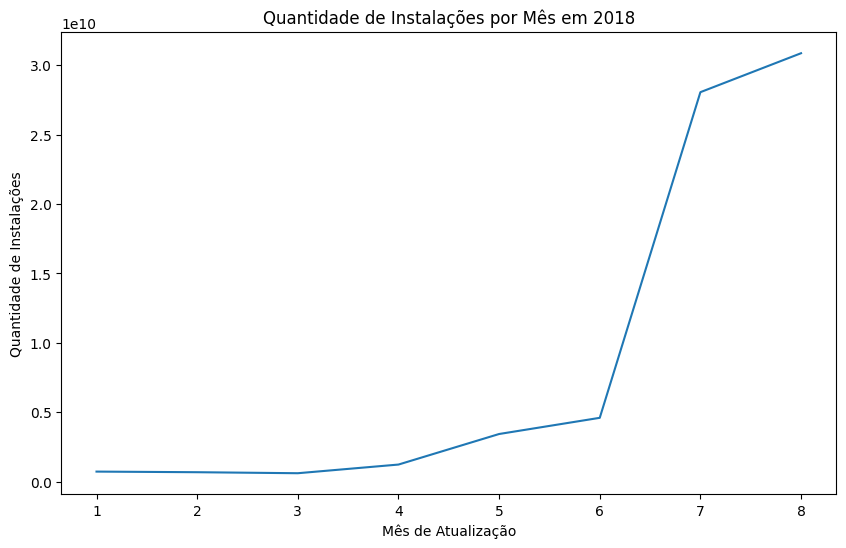

In [34]:
from datetime import datetime

# Criando uma nova coluna para o ano de atualização
df['Update Year'] = df['Last Updated'].dt.year

# Filtrando os dados para o ano de 2018
df_2018 = df[df['Update Year'] == 2018]

# Agrupando por mês de atualização e somando as instalações
grouped_2018 = df_2018.groupby(df_2018['Last Updated'].dt.month)['Installs'].sum().reset_index()

# Plotando o resultado
plt.figure(figsize=(10,6))
plt.plot(grouped_2018['Last Updated'], grouped_2018['Installs'])
plt.xlabel('Mês de Atualização')
plt.ylabel('Quantidade de Instalações')
plt.title('Quantidade de Instalações por Mês em 2018')
plt.show()